# 02 — Insights gerais (todas as plataformas)

**Pergunta:** o que leva um post a ter mais **views, likes, shares e comentários**? Para quem cada tipo de post fala?

| # | Frente | Método |
|---|---|---|
| 1 | Definir "post top" | top 10% de cada métrica |
| 2 | Atributos dos tops | lift + qui² + correção FDR (Benjamini-Hochberg) |
| 3 | Combinações vencedoras | regras de associação de 2 atributos (lift) |
| 4 | Previsibilidade | gradient boosting com validação cruzada (R², AUC) + árvore legível |
| 5 | Clusterização | K-Means em 2 espaços (desempenho; atributos) × nulo por permutação |
| 6 | Audiência | resíduos ajustados, V de Cramér, índice de engajamento por segmento |
| 7 | NLP nos comentários | sentimento (VADER), palavras distintivas (log-odds), tópicos (NMF) |
| 8 | Validação do método | efeito plantado (+2% views) precisa ser encontrado |

**Como ler:** *lift* = quanto um atributo aparece mais entre os tops do que na base (1,0 = igual; 1,2 = 20% a mais).
*q-value* = p-value corrigido para os milhares de testes feitos; só q < 0,05 conta como achado.

In [1]:
# Setup: make solution/src importable and load the posts with derived features.
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "solution" / "src").exists())
sys.path.insert(0, str(ROOT / "solution" / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from social_insights import data, top_performers as tp, clustering as cl, drivers as dr, audience as au, nlp, validation as va, plots

plots.apply_style()
pd.set_option("display.float_format", "{:.4f}".format)
df = data.load_posts(ROOT)
print(f"{len(df):,} posts")

52,214 posts


## 1. O que é um post top?

,média,corte top 10%,máximo,top / média
views,10100.2800,10228.0000,10551.0000,1.0100
likes,1510.2700,1560.0000,1668.0000,1.0300
shares,300.0200,322.0000,380.0000,1.0700
comments_count,200.0200,218.0000,258.0000,1.0900


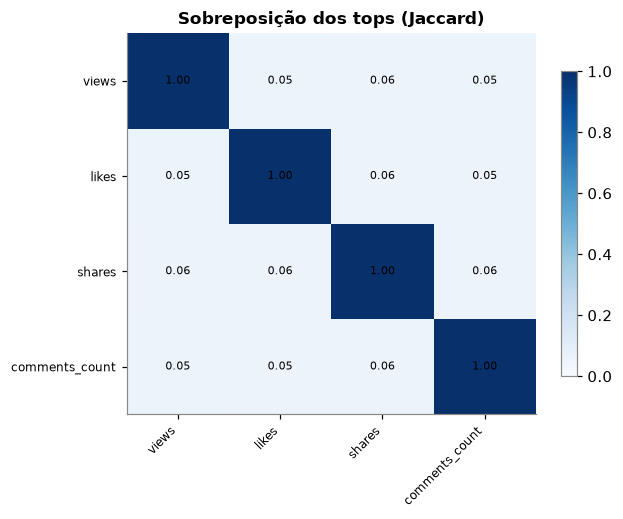

In [2]:
TOPS = {m: tp.flag_top(df, m) for m in data.METRICS}
thresholds = pd.DataFrame({m: {"média": df[m].mean(), "corte top 10%": df[m].quantile(tp.TOP_QUANTILE),
                               "máximo": df[m].max(), "top / média": df[m].quantile(tp.TOP_QUANTILE) / df[m].mean()}
                           for m in data.METRICS}).T
display(thresholds.round(2))

fig, ax = plt.subplots(figsize=(6, 4.5))
plots.heatmap(ax, tp.top_overlap(df, data.METRICS), "Sobreposição dos tops (Jaccard)", cmap="Blues", vmin=0, vmax=1, fmt="{:.2f}")
plt.show()

**Leitura:** um post top em views fica só ~1,3% acima da média, e ser top em views não aumenta a chance de ser top em likes.
A sobreposição (~0,05) é exatamente a esperada se as métricas forem sorteadas de forma independente (0,01 / 0,19).

## 2. Quais atributos aparecem mais entre os tops?

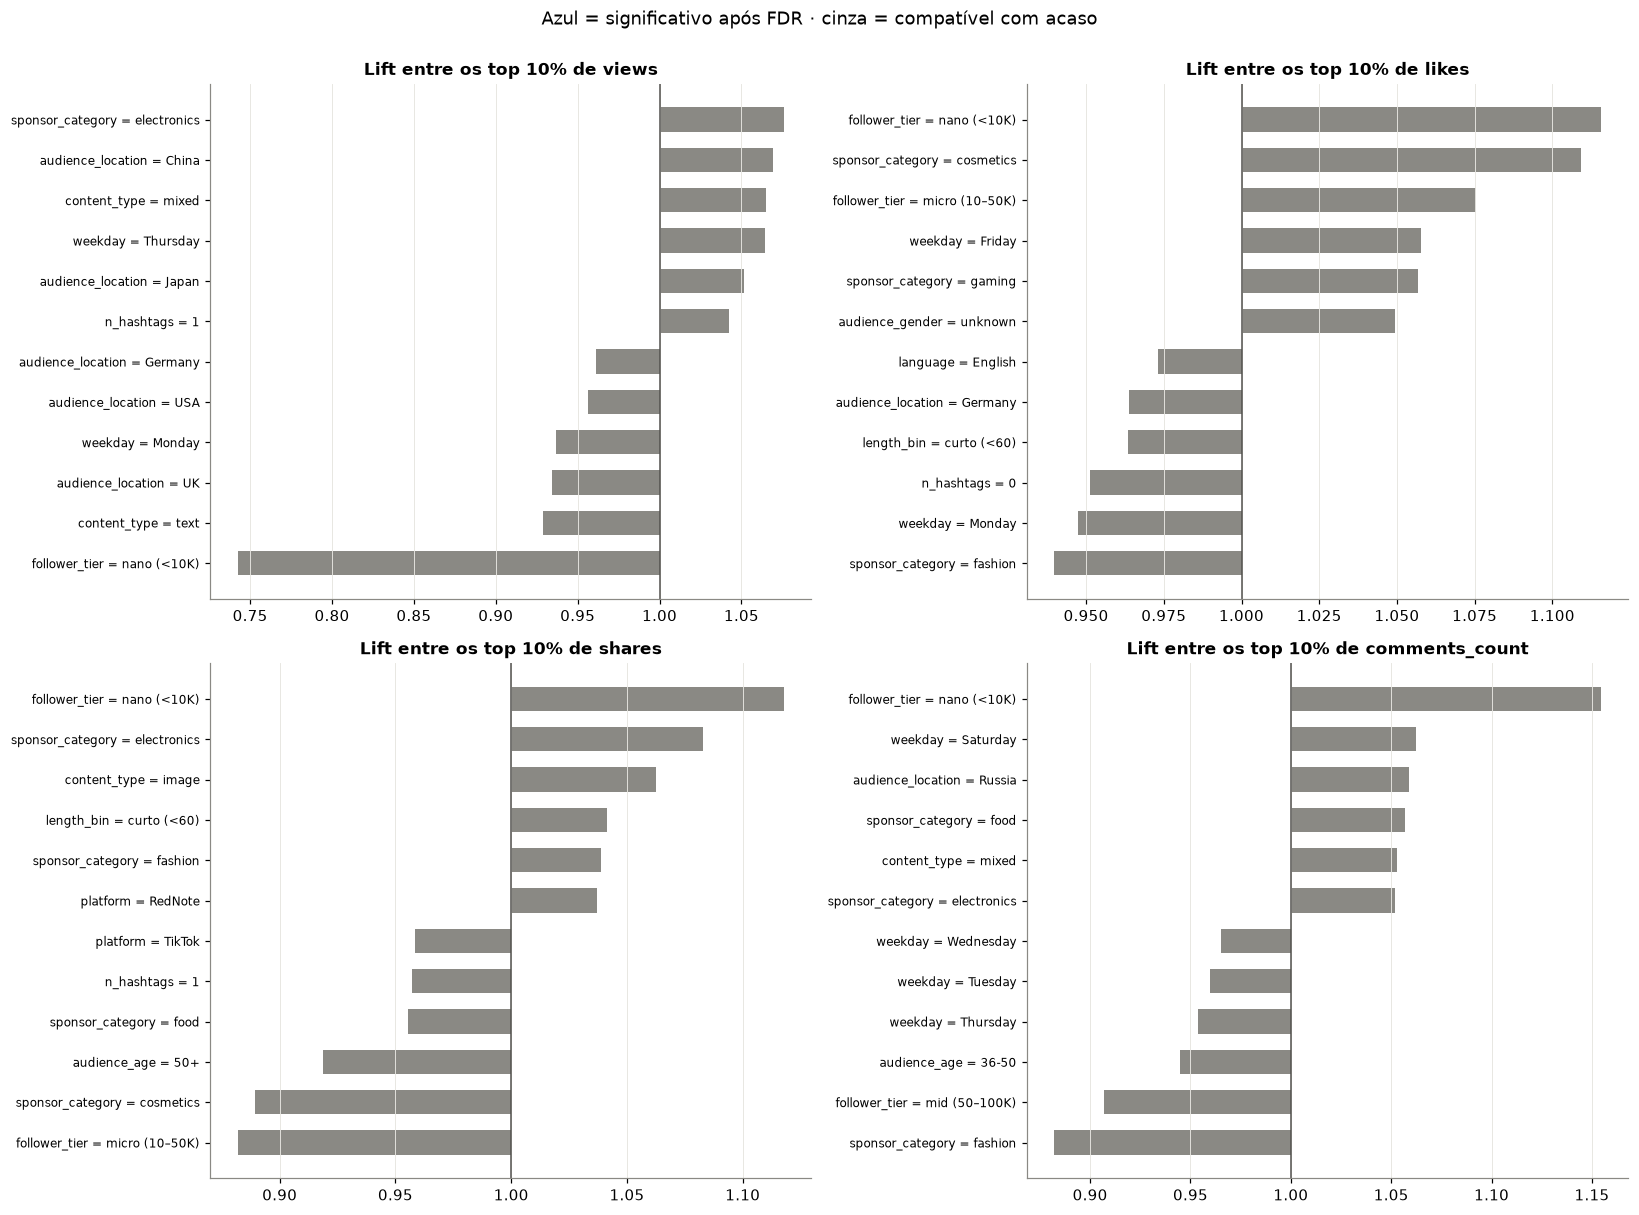

,testes,"p<0,05 (sem correção)",falsos positivos esperados,significativos (FDR),maior lift
views,69.0000,6.0000,3.4000,0.0000,1.0759
likes,69.0000,2.0000,3.4000,0.0000,1.1155
shares,69.0000,3.0000,3.4000,0.0000,1.1178
comments_count,69.0000,3.0000,3.4000,0.0000,1.1543


In [3]:
LIFTS = {m: tp.lift_table(df, TOPS[m], data.FEATURES) for m in data.METRICS}

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for ax, m in zip(axes.flat, data.METRICS):
    plots.lift_bars(ax, LIFTS[m], f"Lift entre os top 10% de {m}")
fig.suptitle("Azul = significativo após FDR · cinza = compatível com acaso", y=1.0)
fig.tight_layout(); plt.show()

pd.DataFrame({m: {"testes": len(t), "p<0,05 (sem correção)": int((t.p_value < 0.05).sum()),
                  "falsos positivos esperados": tp.expected_false_positives(t),
                  "significativos (FDR)": int(t.significant.sum()), "maior lift": t.lift.max()}
              for m, t in LIFTS.items()}).T

**Leitura:** os lifts vão de ~0,75 a ~1,15. Os extremos aparecem nos grupos pequenos (ex.: creators nano = 1% dos posts), porque amostra pequena gera oscilação grande. O número de p < 0,05 é o esperado por acaso.
**Nenhum atributo sobrevive à correção.** Uma análise sem correção (o que um LLM costuma entregar) reportaria esses falsos positivos como insights.

## 3. Combinações de atributos (regras de associação)

In [4]:
PAIRS = {m: tp.pair_lift_table(df, TOPS[m], data.FEATURES) for m in data.METRICS}
summary = pd.DataFrame({m: {"regras testadas": len(t), "p<0,05 (sem correção)": int((t.p_value < 0.05).sum()),
                            "falsos positivos esperados": tp.expected_false_positives(t),
                            "significativas (FDR)": int(t.significant.sum())} for m, t in PAIRS.items()}).T
display(summary)
display(Markdown("**Top 8 combinações por lift (views) — note os q-values:**"))
PAIRS["views"].head(8)[["feature", "value", "n", "top_rate", "lift", "p_value", "q_value"]]

,regras testadas,"p<0,05 (sem correção)",falsos positivos esperados,significativas (FDR)
views,2108.0000,101.0000,105.4000,0.0000
likes,2108.0000,60.0000,105.4000,0.0000
shares,2108.0000,106.0000,105.4000,0.0000
comments_count,2108.0000,91.0000,105.4000,0.0000


**Top 8 combinações por lift (views) — note os q-values:**

,feature,value,n,top_rate,lift,p_value,q_value
0,language & follower_tier,Japanese & micro (10–50K),225,0.1511,1.4980,0.0165,1.0000
1,sponsor_category & audience_age_distribution,food & 36-50,562,0.1477,1.4641,0.0003,0.2410
2,sponsor_category & audience_gender_distribution,food & unknown,369,0.1436,1.4239,0.0080,1.0000
3,content_type & sponsor_category,mixed & cosmetics,354,0.1412,1.4002,0.0146,1.0000
4,follower_tier & audience_location,micro (10–50K) & Brazil,273,0.1392,1.3799,0.0447,1.0000
5,audience_age_distribution & audience_location,50+ & Brazil,360,0.1389,1.3769,0.0206,1.0000
6,length_bin & sponsor_category,longo (180–360) & electronics,897,0.1371,1.3594,0.0003,0.2410
7,sponsor_category & audience_location,electronics & Brazil,442,0.1357,1.3457,0.0180,1.0000


**Leitura:** a "melhor" combinação (ex.: idioma japonês + creator micro) tem lift de ~1,5, ou seja, 50% mais tops. Parece um insight, mas tem q = 1,0.
Com 2.108 regras testadas, ~105 passam de p < 0,05 por puro acaso, e foi exatamente isso que aconteceu. **Este é o erro que separa análise de achismo.**

## 4. Dá para prever o desempenho a partir dos atributos?

In [5]:
reg = pd.DataFrame([dr.cv_regression(df, m, data.FEATURES) for m in data.METRICS]).set_index("target")
reg["AUC top 10%"] = [dr.cv_top_classifier(df, TOPS[m], data.FEATURES) for m in data.METRICS]
reg

,r2_model,r2_std,r2_baseline,AUC top 10%
target,,,,
views,-0.0003,0.0003,-0.0000,0.5049
likes,-0.0005,0.0002,-0.0001,0.4945
shares,-0.0007,0.0003,-0.0000,0.4994
comments_count,-0.0006,0.0003,-0.0000,0.4977


In [6]:
display(Markdown("**Importância por permutação (views):**"))
display(dr.importance_table(df, "views", data.FEATURES))
print(dr.surrogate_tree(df, TOPS["views"], data.FEATURES))

**Importância por permutação (views):**

,feature,importance,std
0,n_hashtags,0.0004,0.0003
1,content_length,0.0003,0.0002
2,follower_count,0.0003,0.0002
3,daypart_tarde,0.0002,0.0001
4,content_type_image,0.0001,0.0001
5,content_category_beauty,0.0001,0.0000
6,platform_Instagram,0.0001,0.0001
7,audience_age_distribution_36-50,0.0001,0.0000
8,content_category_tech,0.0001,0.0000
9,weekday_Thursday,0.0001,0.0000


|--- content_length <= 580.50
|   |--- follower_count <= 15858.00
|   |   |--- n_hashtags <= 2.50
|   |   |   |--- weights: [205.20, 109.05] class: 0
|   |   |--- n_hashtags >  2.50
|   |   |   |--- weights: [191.85, 158.61] class: 0
|   |--- follower_count >  15858.00
|   |   |--- follower_count <= 27041.00
|   |   |   |--- weights: [269.71, 371.75] class: 1
|   |   |--- follower_count >  27041.00
|   |   |   |--- weights: [24925.30, 25120.61] class: 1
|--- content_length >  580.50
|   |--- audience_gender_distribution_female <= 0.50
|   |   |--- weights: [314.19, 153.66] class: 0
|   |--- audience_gender_distribution_female >  0.50
|   |   |--- weights: [200.75, 193.31] class: 0



**Leitura:** R² ≈ 0 (o modelo não supera "chutar a média") e AUC ≈ 0,50 (cara ou coroa).
A importância por permutação fica ≈ 0. As poucas folhas da árvore com taxa de top diferente são pequenas e não se sustentam na validação cruzada.
Nenhuma combinação de plataforma, formato, categoria, creator, horário ou audiência explica o alcance.

## 5. Clusterização

Dois espaços:
- **Desempenho** (log de views, likes, shares, comments): existem "tipos" naturais de post?
- **Atributos** (one-hot de conteúdo + audiência → SVD): existem "receitas" de post?

O K-Means **sempre** devolve k grupos, mesmo em ruído. Por isso cada silhueta é comparada com um **nulo**: os mesmos dados com cada coluna embaralhada (mantém as distribuições e destrói as relações).
Ganho ≈ 0 → os clusters são artefato do algoritmo.

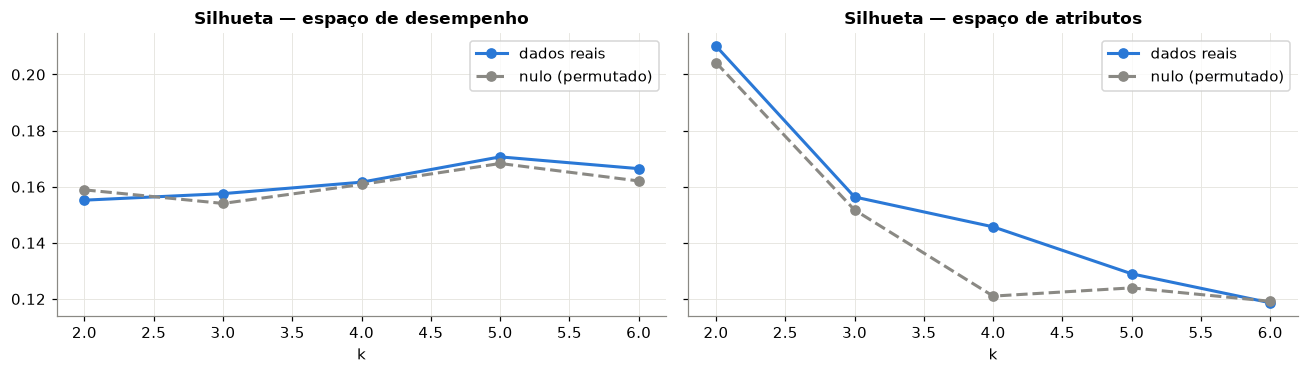

k  silhouette  silhouette_null    gain
espaço                                              
desempenho 0  2      0.1550           0.1590 -0.0040
           1  3      0.1580           0.1540  0.0030
           2  4      0.1620           0.1610  0.0010
           3  5      0.1710           0.1680  0.0020
           4  6      0.1660           0.1620  0.0040
atributos  0  2      0.2100           0.2040  0.0060
           1  3      0.1560           0.1520  0.0050
           2  4      0.1460           0.1210  0.0250
           3  5      0.1290           0.1240  0.0050
           4  6      0.1190           0.1190 -0.0010

In [7]:
X_perf = cl.performance_space(df, data.METRICS)
X_attr = cl.attribute_space(df, data.FEATURES)
structure = {"desempenho": cl.structure_test(X_perf), "atributos": cl.structure_test(X_attr)}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, (name, t) in zip(axes, structure.items()):
    ax.plot(t.k, t.silhouette, "o-", color=plots.BLUE, linewidth=2, label="dados reais")
    ax.plot(t.k, t.silhouette_null, "o--", color=plots.GRAY, linewidth=2, label="nulo (permutado)")
    ax.set_title(f"Silhueta — espaço de {name}"); ax.set_xlabel("k"); ax.legend()
fig.tight_layout(); plt.show()
pd.concat(structure, names=["espaço"]).round(3)

In [8]:
K = 4
perf_labels = cl.fit_kmeans(X_perf, K)
display(Markdown("**Clusters de desempenho → o que há neles?** (médias das métricas e atributos mais sobre-representados)"))
display(cl.profile_clusters(df, perf_labels, data.METRICS))
display(cl.dominant_attributes(df, perf_labels, data.FEATURES).round(3))

attr_labels = cl.fit_kmeans(X_attr, K)
display(Markdown("**Clusters de atributos → desempenham diferente?**"))
display(cl.dominant_attributes(df, attr_labels, data.FEATURES).round(3))
cl.profile_clusters(df, attr_labels, data.METRICS)

**Clusters de desempenho → o que há neles?** (médias das métricas e atributos mais sobre-representados)

,views,likes,shares,comments_count,n
cluster,,,,,
0,10051.6000,1470.9000,303.9000,204.6000,12998.0000
1,10108.1000,1514.0000,303.6000,183.3000,12632.0000
2,10136.9000,1513.9000,280.7000,203.3000,12801.0000
3,10105.1000,1540.6000,311.0000,208.0000,13783.0000
Kruskal p,0.0000,0.0000,0.0000,0.0000,NaN


,cluster,feature,value,lift
21,0,follower_tier,nano (<10K),1.1860
30,0,n_hashtags,4,1.0500
15,0,language,Japanese,1.0420
117,1,sponsor_category,fashion,1.0380
85,1,language,Spanish,1.0340
73,1,platform,YouTube,1.0330
159,2,follower_tier,nano (<10K),1.0420
164,2,n_hashtags,0,1.0370
188,2,sponsor_category,gaming,1.0300
254,3,sponsor_category,electronics,1.0660


**Clusters de atributos → desempenham diferente?**

,cluster,feature,value,lift
42,0,sponsor_category,fashion,2.3850
43,0,sponsor_category,food,2.3630
40,0,sponsor_category,cosmetics,2.3570
80,1,follower_tier,mega (500K+),2.0060
103,1,sponsor_category,Not sponsors,1.7460
102,1,is_sponsored,False,1.7460
141,2,follower_tier,nano (<10K),2.0090
138,2,follower_tier,macro (100–500K),1.9970
140,2,follower_tier,mid (50–100K),1.9960
230,3,sponsor_category,travel,2.4180


,views,likes,shares,comments_count,n
cluster,,,,,
0,10101.1000,1510.0000,300.0000,199.9000,11124.0000
1,10101.0000,1510.3000,300.2000,200.1000,14905.0000
2,10099.3000,1510.2000,299.9000,199.9000,14995.0000
3,10099.8000,1510.6000,299.9000,200.1000,11190.0000
Kruskal p,0.4210,0.5340,0.3190,0.5030,NaN


**Leitura:**
- **Clusters de desempenho:** o ganho sobre o nulo é ≈ 0, então o K-Means só fatia uma nuvem única ("um pouco mais de likes", "um pouco mais de shares").
  O Kruskal p = 0 ali é circular (os clusters foram feitos com as próprias métricas), e os atributos dentro deles têm lift ≈ 1,0–1,2.
- **Clusters de atributos:** separam bem receitas de post (patrocinado de moda/comida, creators mega orgânicos...), mas **todos têm as mesmas métricas** (Kruskal p > 0,3).

## 6. Audiência: quem consome cada tipo de post?

In [9]:
CONTENT_FOR_AUDIENCE = ["platform", "content_type", "content_category", "language", "follower_tier", "is_sponsored"]
assoc = au.association_summary(df, CONTENT_FOR_AUDIENCE, data.AUDIENCE)
assoc["significativo"] = assoc.p_value < 0.05 / len(assoc)
assoc.round(4)

,content,audience,cramers_v,p_value,significativo
0,is_sponsored,audience_location,0.0129,0.2787,False
1,platform,audience_location,0.0123,0.2887,False
2,content_category,audience_location,0.0116,0.4434,False
3,follower_tier,audience_location,0.0116,0.4632,False
4,language,audience_location,0.0113,0.5378,False
5,language,audience_age_distribution,0.0110,0.0631,False
6,content_type,audience_location,0.0100,0.7820,False
7,language,audience_gender_distribution,0.0098,0.2329,False
8,content_type,audience_age_distribution,0.0095,0.2856,False
9,follower_tier,audience_gender_distribution,0.0092,0.3408,False


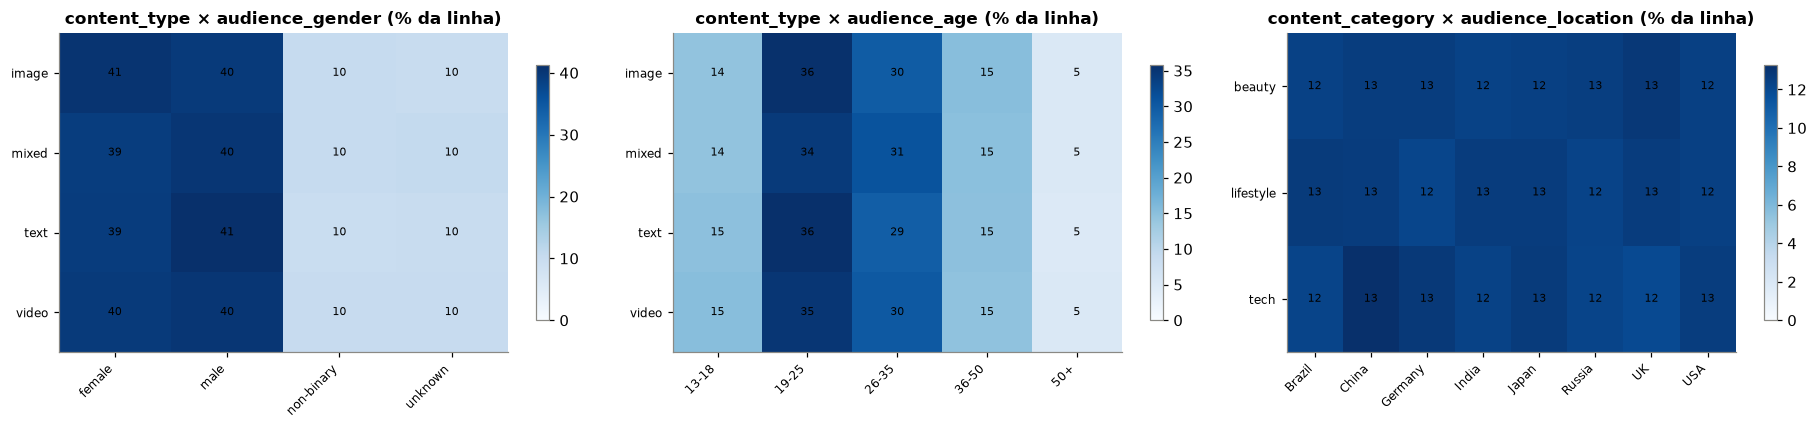

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, (by, aud) in zip(axes, [("content_type", "audience_gender_distribution"),
                                ("content_type", "audience_age_distribution"),
                                ("content_category", "audience_location")]):
    plots.heatmap(ax, au.audience_mix(df, by, aud) * 100, f"{by} × {aud.replace('_distribution', '')} (% da linha)",
                  cmap="Blues", vmin=0, fmt="{:.0f}")
fig.tight_layout(); plt.show()

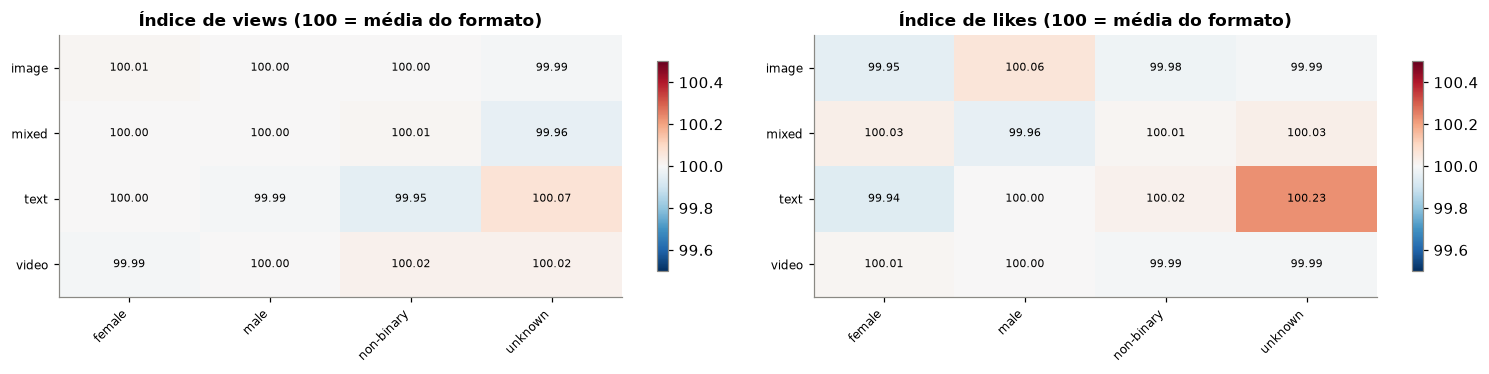

**p-value (Kruskal): dentro de cada formato, o segmento de audiência muda as views?**

,audience_gender_distribution,audience_age_distribution,audience_location
content_type,,,
image,0.9903,0.5065,0.0769
mixed,0.8567,0.5926,0.3346
text,0.3585,0.7576,0.1286
video,0.4071,0.2770,0.9415


In [11]:
# Who engages most? Views/likes per (content type × audience), indexed to the content type's mean (100 = average).
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
for ax, m in zip(axes, ["views", "likes"]):
    idx = au.engagement_by_segment(df, "content_type", "audience_gender_distribution", m)
    plots.heatmap(ax, idx, f"Índice de {m} (100 = média do formato)", vmin=99.5, vmax=100.5, fmt="{:.2f}")
fig.tight_layout(); plt.show()
display(Markdown("**p-value (Kruskal): dentro de cada formato, o segmento de audiência muda as views?**"))
pd.DataFrame({aud: au.interaction_pvalues(df, "content_type", aud, "views") for aud in data.AUDIENCE})

In [12]:
rows = []
for by in CONTENT_FOR_AUDIENCE:
    for aud in data.AUDIENCE:
        rows.append(au.strongest_cells(df, by, aud).assign(content=by, audience=aud).rename(columns={by: "valor", aud: "segmento"}))
cells = pd.concat(rows)
print(f"Células com |resíduo ajustado| > {au.RESIDUAL_THRESHOLD}: {len(cells)}")
cells

Células com |resíduo ajustado| > 3.0: 0


,valor,segmento,residual,content,audience


**Leitura:** o mix de audiência é o mesmo em todo formato, categoria e plataforma (V de Cramér < 0,02, ou seja, independência).
Exemplo: vídeo tem 40% de público feminino, e imagem e texto também. Os índices de engajamento por segmento ficam a ±0,3% de 100.

## 7. NLP nos comentários

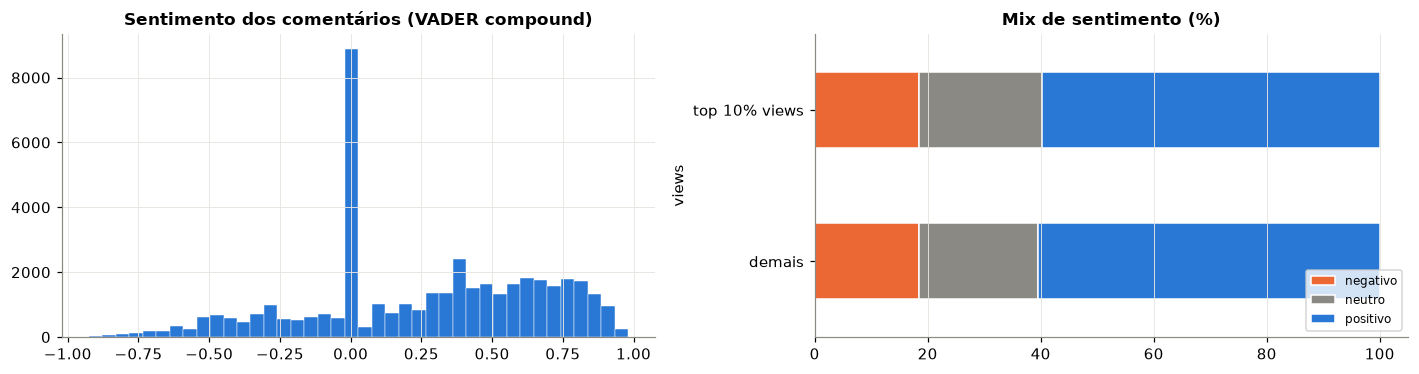

,mean_top,mean_rest,diff,p_value
views,0.2532,0.2537,-0.0006,0.9794
likes,0.2560,0.2534,0.0026,0.7725
shares,0.2538,0.2536,0.0001,0.9254
comments_count,0.2512,0.2540,-0.0027,0.8906


In [13]:
df["sentiment"] = nlp.sentiment(df["comments_text"])
df["sentiment_label"] = nlp.sentiment_label(df["sentiment"])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].hist(df["sentiment"].dropna(), bins=40, color=plots.BLUE, edgecolor="white", linewidth=0.3)
axes[0].set_title("Sentimento dos comentários (VADER compound)")
mix = pd.crosstab(TOPS["views"].map({True: "top 10% views", False: "demais"}), df["sentiment_label"], normalize="index") * 100
mix.plot.barh(stacked=True, ax=axes[1], color=[plots.ORANGE, plots.GRAY, plots.BLUE], width=0.5, edgecolor="white")
axes[1].set_title("Mix de sentimento (%)"); axes[1].legend(loc="lower right", fontsize=8); axes[1].grid(axis="y", visible=False)
fig.tight_layout(); plt.show()

pd.DataFrame({m: nlp.compare_sentiment(df["sentiment"], TOPS[m]) for m in data.METRICS}).T

In [14]:
bottom_views = df["views"] <= df["views"].quantile(1 - tp.TOP_QUANTILE)
kw = nlp.log_odds_keywords(df.loc[TOPS["views"], "comments_text"], df.loc[bottom_views, "comments_text"], top_n=10)
display(Markdown("**Palavras mais típicas dos comentários: top 10% vs. bottom 10% de views** (|z| > 1,96 = significativo)"))
kw

**Palavras mais típicas dos comentários: top 10% vs. bottom 10% de views** (|z| > 1,96 = significativo)

,word,count_a,count_b,z
0,ball,89,56,1.6153
1,suggest,88,56,1.5726
2,open,75,47,1.4936
3,improve,86,56,1.4863
4,evidence,84,57,1.3456
5,guy,90,62,1.3455
6,admit,86,59,1.3280
7,buy,91,64,1.2868
8,build,85,59,1.2842
9,quality,75,52,1.2094


In [15]:
display(Markdown("**Sugestão:** aplicar o mesmo método à *legenda* e às *hashtags*, que o time controla (os comentários são consequência, não causa)."))
display(nlp.log_odds_keywords(df.loc[TOPS["views"], "content_description"], df.loc[bottom_views, "content_description"], top_n=5))
display(nlp.log_odds_keywords(df.loc[TOPS["views"], "hashtags"].fillna("").str.replace(",", " "),
                              df.loc[bottom_views, "hashtags"].fillna("").str.replace(",", " "), top_n=5, min_count=10))
display(Markdown("**Tópicos dos comentários (NMF):**"))
nlp.topics(df["comments_text"])

**Sugestão:** aplicar o mesmo método à *legenda* e às *hashtags*, que o time controla (os comentários são consequência, não causa).

,word,count_a,count_b,z
0,series,116,78,1.6238
1,cover,113,80,1.4201
2,artist,121,87,1.4118
3,world,128,93,1.4117
4,blood,108,76,1.4095
754,theory,89,125,-1.3716
755,network,87,125,-1.4577
756,bed,84,124,-1.5526
757,feeling,79,118,-1.5567
758,week,73,118,-1.8327


,word,count_a,count_b,z
0,cause,16,3,1.7487
1,administration,18,6,1.4554
2,political,21,8,1.4414
3,truth,19,7,1.4032
4,professor,22,9,1.3984
754,similar,5,17,-1.4262
755,deep,3,14,-1.4907
756,discussion,8,23,-1.4983
757,official,10,27,-1.5524
758,represent,7,26,-1.8466


**Tópicos dos comentários (NMF):**

/home/half/Documents/desafios/ai-master-challenge/submissions/rafael/.venv/lib64/python3.14/site-packages/sklearn/decomposition/_nmf.py:1723: ConvergenceWarning: Maximum number of iterations 400 reached. Increase it to improve convergence.
  warnings.warn(


,tópico 1,tópico 2,tópico 3,tópico 4,tópico 5,tópico 6
0,choose,car,public,early,scientist,certain
1,field,spring,able,political,glass,yard
2,participant,baby,data,attack,finally,wall
3,foreign,everybody,blood,measure,brother,wife
4,image,answer,lose,culture,speak,question
5,eat,million,black,impact,right,free
6,man,traditional,card,push,run,economy
7,work,old,environment,just,believe,threat


**Leitura:** o sentimento é igual em tops e demais (p > 0,05), e nenhuma palavra passa de |z| = 1,96.
Os tópicos são misturas aleatórias de palavras ("car, spring, baby"), o que confirma que os textos são gerados (Faker), sem semântica de marketing.

## 8. Validação do método (controle positivo)
Se os dados tivessem sinal, o pipeline acharia? Plantamos um efeito pequeno e realista: **+2% de views em vídeos de tech no TikTok** (≈ 2% dos posts).

Posts afetados: **1,228** (2.4%)

,feature,value,n,lift,q_value
0,platform & content_category,TikTok & tech,2038,4.4250,0.0000
1,content_type & content_category,video & tech,6232,2.0202,0.0000
2,platform & content_type,TikTok & video,6239,2.0035,0.0000
3,platform & sponsor_category,TikTok & fashion,738,1.9060,0.0000
4,content_category & follower_tier,tech & micro (10–50K),470,1.8466,0.0000
5,content_category & language,tech & Japanese,1056,1.8327,0.0000


,target,r2_model,r2_std,r2_baseline
dados,,,,
originais,views,-0.0003,0.0003,-0.0000
com efeito +2%,views,0.0795,0.0052,-0.0000


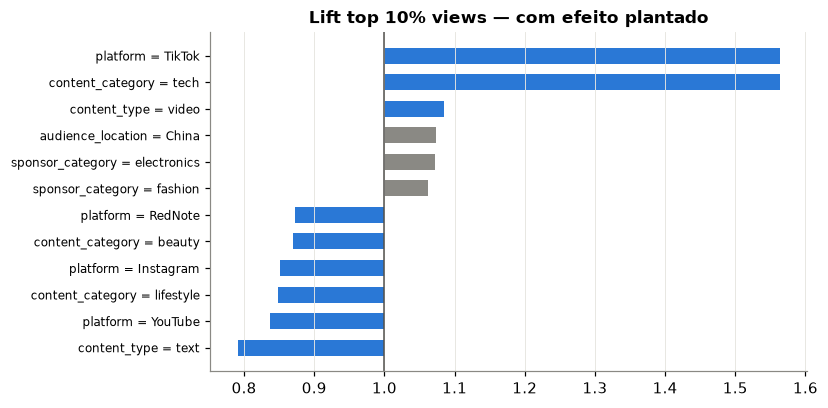

In [16]:
planted = va.demo_segment(df)
injected = va.inject_uplift(df, planted, "views", uplift=0.02)
top_inj = tp.flag_top(injected, "views")

display(Markdown(f"Posts afetados: **{planted.sum():,}** ({planted.mean():.1%})"))
display(tp.summarize_significant(tp.pair_lift_table(injected, top_inj, data.FEATURES), 6)[["feature", "value", "n", "lift", "q_value"]])
display(pd.DataFrame([dr.cv_regression(df, "views", data.FEATURES) | {"dados": "originais"},
                      dr.cv_regression(injected, "views", data.FEATURES) | {"dados": "com efeito +2%"}]).set_index("dados"))
fig, ax = plt.subplots(figsize=(7, 4))
plots.lift_bars(ax, tp.lift_table(injected, top_inj, data.FEATURES), "Lift top 10% views — com efeito plantado")
plt.show()

**Leitura:** com só +2% de efeito, o pipeline encontra exatamente TikTok × tech × vídeo (q ≈ 0), e o R² sobe de 0 para ~0,08.
**Logo, a ausência de achados nos dados originais é real e não falta de sensibilidade do método.**

## 9. Conclusões (gerais)
1. **Nenhum atributo do post, do creator ou da audiência explica views, likes, shares ou comentários** (testado com lift + FDR, regras de associação, gradient boosting e árvore).
2. **Não há segmentos naturais:** os clusters não superam o nulo por permutação.
3. **A audiência é idêntica entre formatos, categorias e plataformas.** Não existe "público do vídeo" diferente do "público da imagem".
4. **Comentários não diferenciam posts de alto e baixo alcance** (sentimento, palavras e tópicos).
5. **O método é sensível** (detecta um efeito de 2%) e está pronto para rodar com dados reais da empresa.
6. Patrocínio não muda o desempenho → no dataset, **pagar não compra alcance nem engajamento** (ver notebook 03 por plataforma).